# EDA-EXP02 — Anticipatory epidemiological signals, Phase B

New authorized exploratory analysis of frozen publications; primary population:
76 Meta/Tolima municipalities. Five chapters, at most six aggregate figures.
**G5 NOT_APPROVED; champion: not_selected.** No models, policies or EXP-DELTA02.

The [README](../docs/product/experiments/EDA-EXP02/README.md) fixes source identities
and pre-result methods. [Findings](../docs/product/experiments/EDA-EXP02/PHASE_B_FINDINGS.md)
and [conclusions](../docs/product/experiments/EDA-EXP02/PHASE_B_CONCLUSIONS.md)
interpret executed results. Private source/derived rows remain outside Git.

**Executed result:** O2 `EXPLORATORY_SIGNAL_FOUND`, weak descriptive association
and non-identical representation, with substantial overlap with existing state
memory. O1 `NOT_EVALUABLE` because historical geography admission failed. This
supports only considering a bounded future O2 ablation after a new authorization;
it does not justify launching EXP-DELTA02 or adopting a feature.

## 1. Integrity and analysis population

### Fixed design and assumptions

Preserve all benchmark observations, original H5 and frozen decisions. Horizons
stay separate; years are target years (2020/2021/2022/2024), all already consumed.
Use regional H5 history starting 2011-06, ending at 2024-12. Unknown states and
unobserved starts censor episodes. H5 is an experimental proxy, not clinical truth.

O2 primary is months since the last excess month of the latest **fully observed,
completed** episode whose following non-excess clearance is observed **before T**.
Scan only through T−1. Secondary audit is time since that episode's onset:
start recency = end recency + completed duration −1. Choose end recency in advance
because onset recency mixes quiet time and past duration. They share the same
ordered event information; do not test two competing primary features.

Fixed bands: 1–3, 4–6, 7–12, 13–24, ≥25 months; missing history stays unknown.
Support flag: n≥30, ≥5 onsets and ≥5 non-onsets. This is descriptive support,
not inferential power. All sparse strata remain visible. Compare fixed outcome
classes, years, departments, frozen G0 misses and misses shared by four models.
Use quantiles, contingency tables and Spearman; no tests, regressions or search.

Calendar control subtracts within year×department×origin-month means of ranks;
these outcome-conditioned audit summaries are never new input features. They
remove shared calendar-cell means, not local confounding or dependence.
Retrospective observation chronology does not prove operational availability.

In [1]:
import importlib.metadata
import json
import sys
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))

In [2]:
from sat_dengue.configuration import canonical_bytes
from sat_dengue.datasets.legacy_preparation.persistence import publish_bundle
from sat_dengue.experiments.exp03_1_features import PREDICTORS, trajectory_features
from sat_dengue.training_preparation.serialization import bytes_record, json_bytes, serialize_table

KEYS = ["municipality_code", "year_month"]
PAIR = ["horizon", *KEYS]
MODELS = ["R0", "G0_OFF", "G0_ON", "G1_OFF"]
BENCH = "data/processed/benchmark/6cfc7bcf565ebdf7ff11ab3ff79d6d91ce7d2f392958c76aa55d310ba27b6c48"
REGION = (
    "data/processed/canonical_model_table_v1/"
    "ddf4d3be23f7ce2cd874bbdc73fdf0f7b9ae5e6f7055b2761ec23bd31fc15c98"
)
NATIONAL = (
    "data/processed/canonical_model_table_national_v1/"
    "c2267f61c7624f19ea7056c2d891512b12e85d81214145df1d31815d28fc3c29"
)
EDA = "data/processed/eda_exp01/3d0803788eab1bbc92f29410540b184ff11b07ab921b611b5fd5965ed05e356e"
DIAG = (
    "data/processed/benchmark/diagnostico/"
    "874ef99634db44e0e71a3aba9b7195f8762ff5f9327ef0394d27ce77fc8e116c"
)
GEO = (
    "data/processed/eda_exp02/source_admission/"
    "9f95e52f87a6b97d9a92cc7f3f4e26ad5d50062bc93deab3b492ef75b3a091c1"
)
FIGURES = ROOT / "tmp/eda-exp02/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
BANDS = ["1–3", "4–6", "7–12", "13–24", "≥25", "unknown"]
SOURCES, TABLES = {}, {}
plt.rcParams.update(
    {
        "font.size": 11,
        "figure.dpi": 120,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "savefig.facecolor": "white",
    }
)
COLORS = {
    "onset": "#2563a6",
    "no_excess": "#a25b0b",
    "continuation": "#737373",
    "G0 detected": "#2563a6",
    "G0 missed": "#a25b0b",
    "all four missed": "#624a87",
}
pd.set_option("display.max_rows", 18)
pd.set_option("display.max_columns", 12)


def track(rel, expected=None):
    p = ROOT / rel
    assert not p.is_symlink() and p.is_file(), rel
    record = bytes_record(p.read_bytes())
    assert expected is None or record == expected, rel
    SOURCES[rel] = record
    return record


def verify(rel, expected_manifest=None):
    record = track(rel + "/manifest.json")
    assert expected_manifest is None or record["sha256"] == expected_manifest
    m = json.loads((ROOT / rel / "manifest.json").read_text())
    body = {k: v for k, v in m.items() if k != "bundle_id"}
    assert bytes_record(canonical_bytes(body))["sha256"] == Path(rel).name
    assert m["bundle_id"] == Path(rel).name
    assert {p.name for p in (ROOT / rel).iterdir()} == {*m["files"], "manifest.json"}
    for name, expected in m["files"].items():
        assert Path(name).name == name
        track(rel + "/" + name, expected)
    return m


def read(rel, **kwargs):
    return pd.read_csv(ROOT / rel, dtype={"municipality_code": str}, **kwargs)


def savefig(fig, name):
    fig.savefig(FIGURES / (name + ".png"), bbox_inches="tight")
    display(Image(filename=str(FIGURES / (name + ".png"))))
    plt.close(fig)

### Verify immutable sources and exact benchmark pairing

Verify canonical content identities and every payload, including national data,
benchmark diagnosis and prior EDA aggregates. Also verify the benchmark's recorded
upstream files; never execute historical experiments. Compare national/regional
counts and H5 on common keys, without changing either publication.

In [3]:
bm = verify(BENCH, "4ca5b8359c914fc080c80ebf538d7d11bf1c76aa783d9434c1832d478ff15f2f")
verify(REGION, "037445487086f7123ee2bf4b97b9af06b96716e2f24e9ff5160177c59da261d8")
verify(NATIONAL)
verify(EDA, "6c3ff1a8a2c5a97b7306a28b30f0f8f305dbdbb87209025be8b16150dbbc8002")
verify(DIAG)
verify(GEO, "7d8ddd1024e8d17fdd675d1ba34891bccdc68bbc5c16df1452ad17ab040d3f88")
for rel, expected in bm["sources"].items():
    track(rel, expected)
for rel in [
    "docs/product/experiments/contrato.md",
    "docs/product/experiments/EDA-EXP02/PHASE_A_CONCLUSIONS.md",
    "docs/product/experiments/EDA-EXP02/SIGNAL_INVENTORY.csv",
    "docs/product/experiments/EXP03_feature_ablation/ablation-matrix.frozen.yml",
    "docs/product/experiments/EXP03.1_add_pass_info/ablation-matrix.frozen.yml",
    "src/sat_dengue/experiments/exp03_1_features.py",
    "src/sat_dengue/datasets/legacy_preparation/persistence.py",
    "src/sat_dengue/training_preparation/serialization.py",
    "src/sat_dengue/configuration.py",
]:
    track(rel)
b = read(BENCH + "/predictions.csv")
r = read(REGION + "/canonical_model_table_v1.csv")
n = read(NATIONAL + "/canonical_model_table_national_v1.csv")
assert not r.duplicated(KEYS).any() and not n.duplicated(KEYS).any()
assert not b.duplicated([*PAIR, "arm"]).any()
assert set(b.arm) == {*MODELS, "CHANNEL", "PERSISTENCE"}
base = b.loc[b.arm.eq("G0_OFF")].copy().reset_index(drop=True)
assert base.municipality_code.nunique() == 76
assert base.municipality_code.str[:2].value_counts().index.isin(["50", "73"]).all()
assert set(base.target_year) == {2020, 2021, 2022, 2024}
for arm in b.arm.unique():
    arm_rows = b.loc[b.arm.eq(arm)]
    joined = base.merge(arm_rows, on=PAIR, validate="one_to_one", suffixes=("", "_other"))
    assert len(joined) == len(base) == len(arm_rows)
    for c in ["truth", "target_excess", "target_month", "target_year", "origin_zone"]:
        assert joined[c].equals(joined[c + "_other"])
shared = [*KEYS, "dengue_notifications_count", "p75_canal_t", "zona_canal_t"]
regional_national = r.loc[r.year_month.between("2011-06", "2024-12"), shared].merge(
    n[shared], on=KEYS, validate="one_to_one", suffixes=("", "_national")
)
assert len(regional_national) == 12388
for c in shared[2:]:
    assert regional_national[c].equals(regional_national[c + "_national"])
assert n.municipality_code.nunique() == 1122 and len(n) == 182886
assert r.municipality_code.nunique() == 76 and len(r) == 17936
history = r.loc[r.year_month.le("2024-12")].sort_values(KEYS).copy()
assert history.groupby("municipality_code").size().eq(223).all()
for _, g in history.groupby("municipality_code"):
    assert list(g.year_month) == list(pd.period_range("2006-06", "2024-12", freq="M").astype(str))
assert history.loc[history.year_month.ge("2011-06"), "zona_canal_t"].notna().all()
origin = history[
    [
        *KEYS,
        "zona_canal_t",
        "dengue_notifications_count",
        "dengue_notifications_count_lag1",
        "dengue_notifications_count_lag2",
        "dengue_notifications_count_lag3",
        "dengue_notifications_count_lag12",
        "dengue_grave_notifications_count_lag1",
        "p75_canal_t",
    ]
]
analysis = base.merge(origin, on=KEYS, validate="many_to_one", indicator=True)
assert analysis._merge.eq("both").all() and len(analysis) == 5075
analysis = analysis.drop(columns="_merge")
assert analysis.zona_canal_t.eq(analysis.origin_zone).all()
assert not analysis.zona_canal_t.eq("EXCESO").any()
assert np.array_equal(analysis.origin_count, analysis.dengue_notifications_count)
analysis["department"] = analysis.municipality_code.str[:2].map({"50": "Meta", "73": "Tolima"})
analysis["calendar_month"] = analysis.year_month.str[-2:].astype(int)
analysis["outcome"] = np.select(
    [analysis.truth.eq(1), analysis.target_excess.eq(1)],
    ["onset", "continuation"],
    default="no_excess",
)
assert analysis.loc[analysis.horizon.eq(1), "outcome"].ne("continuation").all()
assert all(
    str(pd.Period(t, freq="M") + h) == target
    for t, h, target in analysis[["year_month", "horizon", "target_month"]].itertuples(
        index=False, name=None
    )
)
TABLES["cohort"] = (
    analysis.groupby(["horizon", "department", "outcome"])
    .agg(rows=("truth", "size"), municipalities=("municipality_code", "nunique"))
    .reset_index()
)
assert analysis.groupby("horizon").truth.sum().tolist() == [313, 219]
assert analysis.groupby("horizon").size().tolist() == [2653, 2422]
display(TABLES["cohort"])

,horizon,department,outcome,rows,municipalities
0,1,Meta,no_excess,878,29
1,1,Meta,onset,146,28
2,1,Tolima,no_excess,1462,47
3,1,Tolima,onset,167,44
4,2,Meta,continuation,58,27
5,2,Meta,no_excess,789,29
6,2,Meta,onset,96,26
7,2,Tolima,continuation,71,37
8,2,Tolima,no_excess,1285,47
9,2,Tolima,onset,123,43


## 2. O2 — Recency and ordered local episodes

### Scan completed episodes without future observations

A start needs a known non-excess previous month; a clearance needs the first
known non-excess after the run. Boundary runs are censored. At each origin, emit
history **before** consuming that origin's state. Thus a run cleared at T is
usable only from T+1. If an unknown interrupts history, reset the remembered
completion: it may conceal a newer episode. No completed history means unknown.

The start and end representations differ only by the completed run's duration.
That identity is checked, not treated as evidence for two separate opportunities.

In [4]:
def episode_history(frame):
    rows, episodes = [], []
    for municipality, g in frame.sort_values(KEYS).groupby("municipality_code"):
        previous, previous_month, start, last = None, None, None, None
        for t, zone in g[["year_month", "zona_canal_t"]].itertuples(index=False, name=None):
            month = pd.Period(t, freq="M")
            if previous_month is not None and month != previous_month + 1:
                previous, start, last = None, None, None
            row = {
                "municipality_code": municipality,
                "year_month": t,
                "episode_end_recency": np.nan,
                "episode_start_recency": np.nan,
                "completed_duration": np.nan,
                "episode_start": None,
                "episode_end": None,
                "clearance_month": None,
                "history_status": "no_observed_completed_episode",
            }
            if last is not None:
                s, e, c = last
                row.update(
                    episode_end_recency=month.ordinal - e.ordinal,
                    episode_start_recency=month.ordinal - s.ordinal,
                    completed_duration=e.ordinal - s.ordinal + 1,
                    episode_start=str(s),
                    episode_end=str(e),
                    clearance_month=str(c),
                    history_status="observed_completed_episode",
                )
            rows.append(row)
            current = None if pd.isna(zone) else zone == "EXCESO"
            if current is None:
                start, last = None, None
            elif current and previous is False:
                start = month
            elif current is False and previous is True:
                if start is not None:
                    last = (start, month - 1, month)
                    episodes.append(
                        {
                            "municipality_code": municipality,
                            "episode_start": str(start),
                            "episode_end": str(month - 1),
                            "clearance_month": str(month),
                            "completed_duration": month.ordinal - start.ordinal,
                        }
                    )
                start = None
            previous, previous_month = current, month
    return pd.DataFrame(rows), pd.DataFrame(episodes)


features, episodes = episode_history(history)
known = features.episode_end_recency.notna()
assert (features.loc[known, "clearance_month"] < features.loc[known, "year_month"]).all()
assert (features.loc[known, "episode_end"] < features.loc[known, "clearance_month"]).all()
assert features.loc[known, "episode_end_recency"].ge(2).all()
assert np.array_equal(
    features.loc[known, "episode_start_recency"],
    features.loc[known, "episode_end_recency"] + features.loc[known, "completed_duration"] - 1,
)
analysis = analysis.merge(features, on=KEYS, validate="many_to_one")
assert len(analysis) == 5075
analysis["recency_band"] = (
    pd.cut(analysis.episode_end_recency, bins=[0, 3, 6, 12, 24, np.inf], labels=BANDS[:-1])
    .astype("string")
    .fillna("unknown")
)
analysis["history_known"] = analysis.episode_end_recency.notna()
# Feature publication is private: no frozen score/label copies.
TABLES["signal_rows"] = analysis[
    [
        *PAIR,
        "episode_end_recency",
        "episode_start_recency",
        "completed_duration",
        "episode_start",
        "episode_end",
        "clearance_month",
        "history_status",
    ]
]
TABLES["completed_episodes"] = episodes
TABLES["history_support"] = analysis.groupby(["horizon", "department", "target_year"]).agg(
    rows=("truth", "size"),
    onsets=("truth", "sum"),
    known_rows=("history_known", "sum"),
    municipalities=("municipality_code", "nunique"),
)
TABLES["history_support"]["known_onsets"] = (
    analysis.assign(known_onset=analysis.history_known & analysis.truth.eq(1))
    .groupby(["horizon", "department", "target_year"])
    .known_onset.sum()
)
TABLES["history_support"] = TABLES["history_support"].reset_index()
display(TABLES["history_support"])

,horizon,department,target_year,rows,onsets,known_rows,municipalities,known_onsets
0,1,Meta,2020,281,26,281,29,26
1,1,Meta,2021,318,24,318,29,24
2,1,Meta,2022,210,49,210,29,49
3,1,Meta,2024,215,47,215,29,47
4,1,Tolima,2020,380,43,380,47,43
5,1,Tolima,2021,528,28,528,47,28
6,1,Tolima,2022,483,40,483,47,40
7,1,Tolima,2024,238,56,238,43,56
8,2,Meta,2020,254,17,254,29,17
9,2,Meta,2021,291,20,291,29,20


In [5]:
censoring = []
for dept, codes in [("Meta", "50"), ("Tolima", "73")]:
    part = history.loc[history.municipality_code.str.startswith(codes)]
    known_part = part.loc[part.zona_canal_t.notna()]
    first = known_part.groupby("municipality_code").first()
    last = known_part.groupby("municipality_code").last()
    regional_episodes = episodes.loc[episodes.municipality_code.str.startswith(codes)]
    f = features.loc[features.municipality_code.str.startswith(codes)]
    censoring.append(
        {
            "department": dept,
            "municipalities": part.municipality_code.nunique(),
            "known_state_rows": len(known_part),
            "unknown_state_rows": int(part.zona_canal_t.isna().sum()),
            "left_boundary_excess_runs": int(first.zona_canal_t.eq("EXCESO").sum()),
            "right_boundary_active_runs": int(last.zona_canal_t.eq("EXCESO").sum()),
            "fully_completed_episodes": len(regional_episodes),
            "origins_without_completed_history": int(f.episode_end_recency.isna().sum()),
        }
    )
TABLES["censoring"] = pd.DataFrame(censoring)
display(TABLES["censoring"])

,department,municipalities,known_state_rows,unknown_state_rows,left_boundary_excess_runs,right_boundary_active_runs,fully_completed_episodes,origins_without_completed_history
0,Meta,29,4727,1740,3,14,501,2020
1,Tolima,47,7661,2820,12,12,825,3341


### Quantify class distributions and predeclared recency bands

All benchmark rows remain in the denominator. Quantiles are conditional on
observed completed history; unknowns form an explicit separate group. T+2
continuations remain distinct from no excess. Fixed bands are not alert cutoffs.

,horizon,outcome,rows,known,unknown,onsets,q10,q25,median,q75,q90
0,1,no_excess,2340,2340,0,0,3.0,4.0,8.0,16.0,24.0
1,1,onset,313,313,0,313,2.0,3.0,5.0,11.0,18.8
2,2,continuation,129,129,0,0,2.0,3.0,5.0,9.0,17.4
3,2,no_excess,2074,2074,0,0,3.0,4.0,8.0,16.0,23.0
4,2,onset,219,219,0,219,2.0,3.0,5.0,12.0,19.0


,horizon,recency_band,rows,onsets,municipalities,onset_fraction,supported
0,1,13–24,653,56,72,0.085758,True
1,1,1–3,528,90,75,0.170455,True
2,1,4–6,572,89,76,0.155594,True
3,1,7–12,681,66,76,0.096916,True
4,1,≥25,219,12,40,0.054795,True
5,2,13–24,597,37,72,0.061977,True
6,2,1–3,484,67,75,0.138430,True
7,2,4–6,535,59,76,0.110280,True
8,2,7–12,615,47,76,0.076423,True
9,2,≥25,191,9,37,0.047120,True


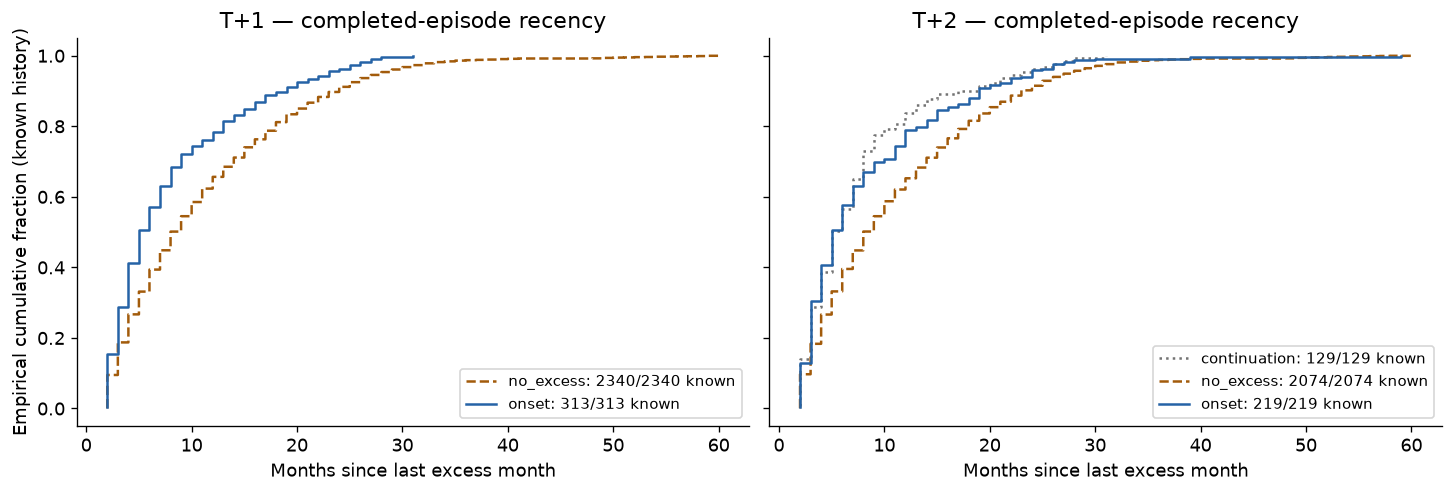

In [6]:
def distributions(frame, by, value="episode_end_recency"):
    rows = []
    for key, g in frame.groupby(by, observed=True, dropna=False, sort=True):
        key = key if isinstance(key, tuple) else (key,)
        v = g[value].dropna()
        row = dict(zip(by, key, strict=True))
        row.update(rows=len(g), known=len(v), unknown=len(g) - len(v), onsets=int(g.truth.sum()))
        for label, q in [("q10", 0.1), ("q25", 0.25), ("median", 0.5), ("q75", 0.75), ("q90", 0.9)]:
            row[label] = float(v.quantile(q)) if len(v) else np.nan
        rows.append(row)
    return pd.DataFrame(rows)


TABLES["outcome_distributions"] = distributions(analysis, ["horizon", "outcome"])
TABLES["stratified_distributions"] = distributions(
    analysis, ["horizon", "target_year", "department", "outcome"]
)
TABLES["recency_bands"] = (
    analysis.groupby(["horizon", "recency_band"], observed=True)
    .agg(
        rows=("truth", "size"),
        onsets=("truth", "sum"),
        municipalities=("municipality_code", "nunique"),
    )
    .reset_index()
)
bands = TABLES["recency_bands"]
bands["onset_fraction"] = bands.onsets / bands.rows
bands["supported"] = bands.rows.ge(30) & bands.onsets.ge(5) & (bands.rows - bands.onsets).ge(5)
TABLES["stratified_bands"] = (
    analysis.groupby(["horizon", "target_year", "department", "recency_band"], observed=True)
    .agg(rows=("truth", "size"), onsets=("truth", "sum"))
    .reset_index()
)
TABLES["stratified_bands"]["onset_fraction"] = (
    TABLES["stratified_bands"].onsets / TABLES["stratified_bands"].rows
)
display(TABLES["outcome_distributions"])
display(bands)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained", sharex=True, sharey=True)
for h, ax in enumerate(axes, 1):
    for outcome, g in analysis.loc[analysis.horizon.eq(h)].groupby("outcome"):
        v = np.sort(g.episode_end_recency.dropna().to_numpy())
        if len(v):
            ax.step(
                v,
                np.arange(1, len(v) + 1) / len(v),
                where="post",
                color=COLORS[outcome],
                linestyle={"onset": "-", "no_excess": "--", "continuation": ":"}[outcome],
                label=f"{outcome}: {len(v)}/{len(g)} known",
            )
    ax.set(title=f"T+{h} — completed-episode recency", xlabel="Months since last excess month")
    ax.legend(fontsize=9, loc="lower right")
axes[0].set_ylabel("Empirical cumulative fraction (known history)")
savefig(fig, "01_recency_distribution")

Completed history is observed on all 5,075 benchmark rows. Onset medians are
5 months in both horizons; no-excess medians are 8. At T+2, continuations also
have median 5: recency alone does not uniquely distinguish a new transition.

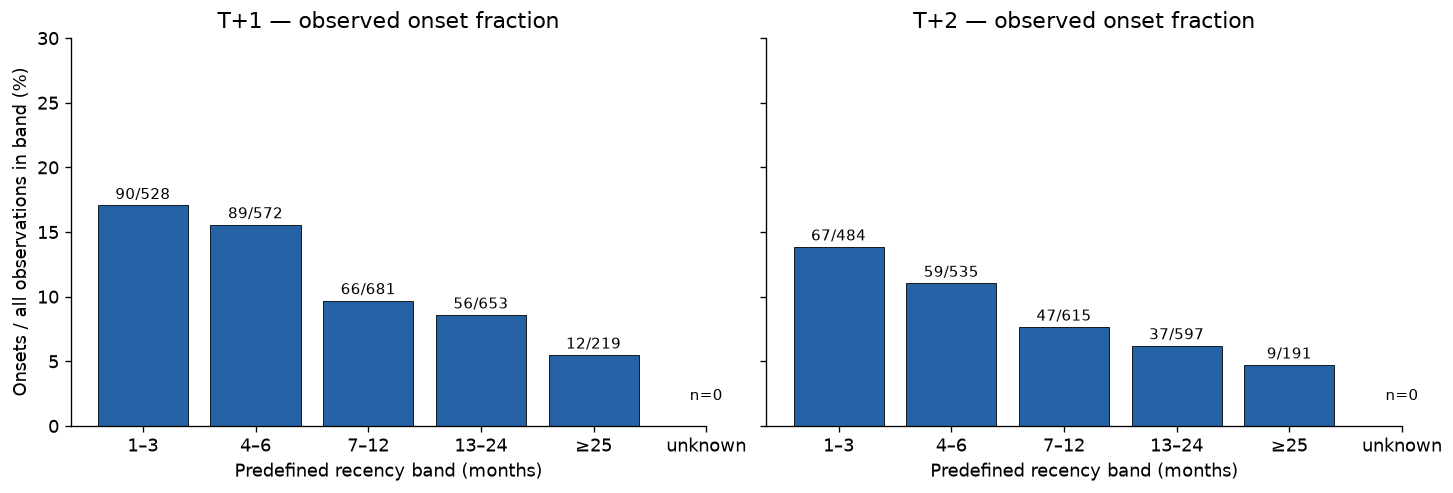

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained", sharey=True)
for h, ax in enumerate(axes, 1):
    g = bands.loc[bands.horizon.eq(h)].set_index("recency_band").reindex(BANDS)
    x = np.arange(len(g))
    ax.bar(x, 100 * g.onset_fraction, color="#2563a6", edgecolor="black", linewidth=0.5)
    for i, row in enumerate(g.itertuples()):
        if pd.notna(row.rows):
            ax.text(
                i,
                100 * row.onset_fraction + 0.5,
                f"{int(row.onsets)}/{int(row.rows)}",
                ha="center",
                fontsize=9,
            )
    ax.text(5, 2, "n=0", ha="center", fontsize=9)
    ax.set_xticks(x, BANDS)
    ax.set(
        title=f"T+{h} — observed onset fraction",
        xlabel="Predefined recency band (months)",
        ylim=(0, 30),
    )
axes[0].set_ylabel("Onsets / all observations in band (%)")
savefig(fig, "02_recency_onset_bands")

Observed onset fractions fall across the fixed recency bands: 17.05% to 5.48%
(T+1) and 13.84% to 4.71% (T+2). These are selected-cohort descriptive fractions,
not forecast risks, alert rules or evidence of incremental model performance.

### Compare years/departments and shared seasonality

Report all eight year/department cells in each horizon plus pooled descriptions.
Rank-centering uses calendar cells of the current horizon/stratum, keeping the
same known-history rows for raw and centered associations. No p-values or
incremental predictive claims follow from these repeated, selected observations.

,scope,horizon,rows,onsets,rho,calendar_centered_rho,supported,department,target_year
6,horizon/target_year/department,1,281,26,-0.008900,-0.051410,True,Meta,2020.0
7,horizon/target_year/department,1,380,43,-0.139802,-0.103068,True,Tolima,2020.0
8,horizon/target_year/department,1,318,24,0.042450,-0.031642,True,Meta,2021.0
9,horizon/target_year/department,1,528,28,-0.125626,-0.143275,True,Tolima,2021.0
10,horizon/target_year/department,1,210,49,-0.077976,-0.068747,True,Meta,2022.0
11,horizon/target_year/department,1,483,40,-0.137568,-0.151209,True,Tolima,2022.0
12,horizon/target_year/department,1,215,47,-0.040833,-0.109657,True,Meta,2024.0
13,horizon/target_year/department,1,238,56,-0.073877,-0.053195,True,Tolima,2024.0
14,horizon/target_year/department,2,254,17,-0.095605,-0.100600,True,Meta,2020.0
15,horizon/target_year/department,2,334,34,-0.014600,-0.019427,True,Tolima,2020.0


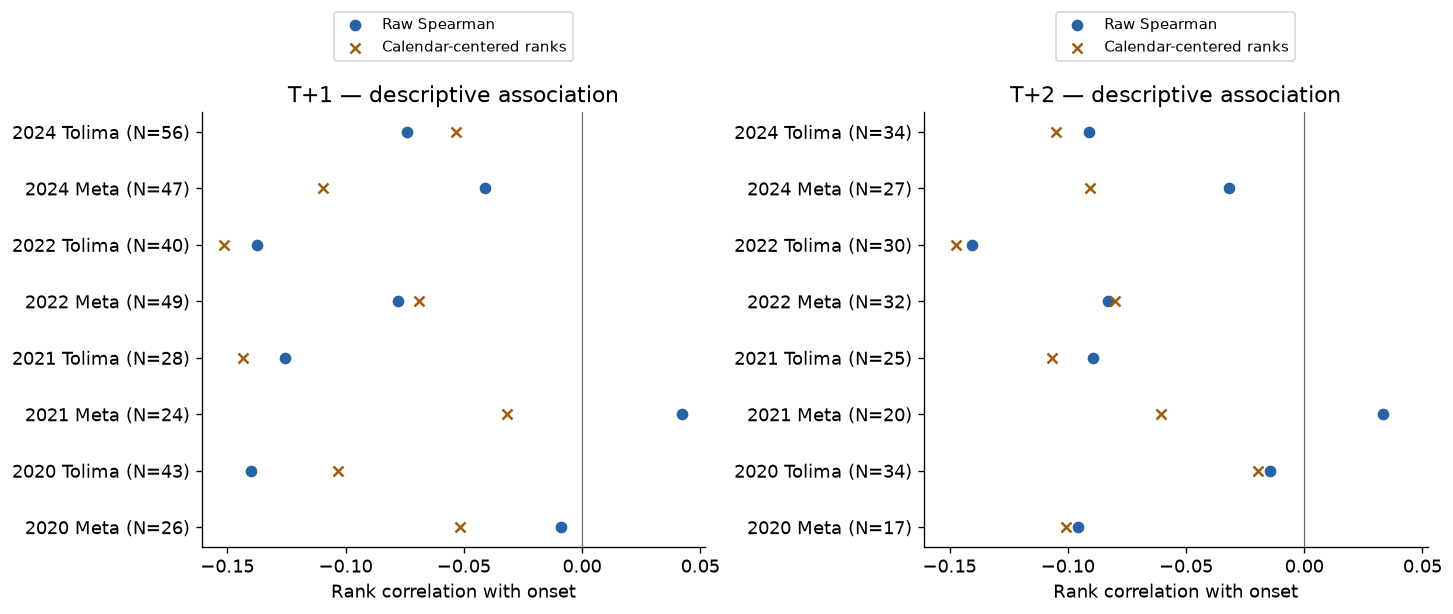

In [8]:
def rank_association(g, x, y="truth"):
    g = g.dropna(subset=[x, y]).copy()
    positive = int(g.truth.sum())
    supported = len(g) >= 30 and positive >= 5 and len(g) - positive >= 5
    if not len(g):
        return {
            "rows": 0,
            "onsets": 0,
            "rho": np.nan,
            "calendar_centered_rho": np.nan,
            "supported": False,
        }
    a, z = g[x].rank(method="average"), g[y].rank(method="average")
    groups = [g.target_year, g.department, g.calendar_month]
    ac, zc = a - a.groupby(groups).transform("mean"), z - z.groupby(groups).transform("mean")
    raw = a.corr(z) if a.nunique() > 1 and z.nunique() > 1 else np.nan
    centered = ac.corr(zc) if ac.std() > 0 and zc.std() > 0 else np.nan
    return {
        "rows": len(g),
        "onsets": positive,
        "rho": raw,
        "calendar_centered_rho": centered,
        "supported": supported,
    }


associations = []
for by in [["horizon"], ["horizon", "department"], ["horizon", "target_year", "department"]]:
    for key, g in analysis.groupby(by, observed=True):
        key = key if isinstance(key, tuple) else (key,)
        associations.append(
            {
                "scope": "/".join(by),
                **dict(zip(by, key, strict=True)),
                **rank_association(g, "episode_end_recency"),
            }
        )
TABLES["associations"] = pd.DataFrame(associations)
display(TABLES["associations"].tail(16))
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained", sharex=True)
for h, ax in enumerate(axes, 1):
    g = (
        TABLES["associations"]
        .loc[
            TABLES["associations"].scope.eq("horizon/target_year/department")
            & TABLES["associations"].horizon.eq(h)
        ]
        .reset_index(drop=True)
    )
    y = np.arange(len(g))
    ax.scatter(g.rho, y, color="#2563a6", marker="o", label="Raw Spearman")
    ax.scatter(
        g.calendar_centered_rho, y, color="#a25b0b", marker="x", label="Calendar-centered ranks"
    )
    ax.set_yticks(
        y, [f"{int(t.target_year)} {t.department} (N={t.onsets})" for t in g.itertuples()]
    )
    ax.axvline(0, color="#666666", linewidth=0.7)
    ax.set(title=f"T+{h} — descriptive association", xlabel="Rank correlation with onset")
    ax.set_xticks([-0.15, -0.10, -0.05, 0, 0.05])
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.10), fontsize=9)
savefig(fig, "03_stratified_associations")

Raw recency/onset Spearman correlations are −0.126/−0.097 (T+1/T+2), with
7/8 negative year/department directions in each horizon. Meta 2021 reverses
raw direction. Calendar-centered ranks are negative in all 16 cells, with
pooled −0.098/−0.092; dependence and local covariates remain uncontrolled.

### Redundancy with existing local representations

Reuse the EXP03.1 historical-zone function with the original covered counts:
T−1…T−6 versus T−7…T−12, no compacting gaps. Check correlation to all six
investigated summaries and existing notification lags. Equal-summary groups with
multiple recencies demonstrate representation variation, not incremental gain;
municipal identity and other local inputs may already encode useful context.

In [9]:
panel = history[[*KEYS, "dengue_notifications_count", "in_epi_coverage"]].rename(
    columns={"in_epi_coverage": "covered"}
)
origins = analysis[KEYS].drop_duplicates().sort_values(KEYS).reset_index(drop=True)
trajectory = trajectory_features(panel, origins)
assert trajectory.channel_trajectory_known.all()
analysis = analysis.merge(trajectory[[*KEYS, *PREDICTORS]], on=KEYS, validate="many_to_one")
controls = [
    "dengue_notifications_count",
    "dengue_notifications_count_lag1",
    "dengue_notifications_count_lag2",
    "dengue_notifications_count_lag3",
    "dengue_notifications_count_lag12",
    "dengue_grave_notifications_count_lag1",
    "p75_canal_t",
    *PREDICTORS,
]
redundancy = []
for h, g in analysis.groupby("horizon"):
    for c in controls + ["episode_start_recency"]:
        valid = g[["episode_end_recency", c]].dropna().astype(float)
        redundancy.append(
            {
                "horizon": h,
                "control": c,
                "rows": len(valid),
                "rho": valid.episode_end_recency.corr(valid[c], method="spearman"),
            }
        )
TABLES["redundancy_correlations"] = pd.DataFrame(redundancy)
variation = []
for h, g in analysis.loc[analysis.history_known].groupby("horizon"):
    groups = g.groupby(list(PREDICTORS), observed=True).episode_end_recency.agg(["size", "nunique"])
    varying = groups["nunique"].gt(1)
    variation.append(
        {
            "horizon": h,
            "known_rows": len(g),
            "summary_groups": len(groups),
            "groups_with_multiple_recencies": int(varying.sum()),
            "rows_in_varying_groups": int(groups.loc[varying, "size"].sum()),
        }
    )
TABLES["representation_variation"] = pd.DataFrame(variation)
display(TABLES["representation_variation"])
display(TABLES["redundancy_correlations"].sort_values("rho", key=abs).tail(8))

,horizon,known_rows,summary_groups,groups_with_multiple_recencies,rows_in_varying_groups
0,1,2653,1277,391,1712
1,2,2422,1191,355,1531


,horizon,control,rows,rho
17,2,dengue_notifications_count_lag3,2422,-0.264292
3,1,dengue_notifications_count_lag3,2653,-0.264343
8,1,channel_warning_recent_6m_count,2653,-0.275863
22,2,channel_warning_recent_6m_count,2422,-0.283588
23,2,channel_excess_recent_6m_count,2422,-0.691801
9,1,channel_excess_recent_6m_count,2653,-0.694494
27,2,episode_start_recency,2422,0.850244
13,1,episode_start_recency,2653,0.852119


### Conditional representation audit

As a direct redundancy check, center recency/onset ranks within identical six
EXP03.1 summaries × target year × department. Keep singletons (zero centered
contribution); expose groups that contain both outcomes and variable recency.
This supplementary descriptive association is not an ablation or adjusted causal
effect. The six-summary matching is fixed by the antecedent, not selected for
favorable association. Sparse cells sharply limit interpretation.

In [10]:
conditional = []
for h, g in analysis.groupby("horizon"):
    matching = [*PREDICTORS, "target_year", "department"]
    x, y = g.episode_end_recency.rank(), g.truth.rank()
    groups = [g[c] for c in matching]
    xc = x - x.groupby(groups).transform("mean")
    yc = y - y.groupby(groups).transform("mean")
    cells = g.groupby(matching, observed=True).agg(
        rows=("truth", "size"),
        onsets=("truth", "sum"),
        recencies=("episode_end_recency", "nunique"),
    )
    mixed = cells.onsets.gt(0) & cells.onsets.lt(cells.rows) & cells.recencies.gt(1)
    supported = mixed & cells.rows.ge(30) & cells.onsets.ge(5) & (cells.rows - cells.onsets).ge(5)
    conditional.append(
        {
            "horizon": h,
            "rows": len(g),
            "rank_correlation": xc.corr(yc),
            "matching_groups": len(cells),
            "mixed_variable_groups": int(mixed.sum()),
            "mixed_rows": int(cells.loc[mixed, "rows"].sum()),
            "mixed_onsets": int(cells.loc[mixed, "onsets"].sum()),
            "supported_groups": int(supported.sum()),
        }
    )
TABLES["conditional_redundancy"] = pd.DataFrame(conditional)
display(TABLES["conditional_redundancy"])

,horizon,rows,rank_correlation,matching_groups,mixed_variable_groups,mixed_rows,mixed_onsets,supported_groups
0,1,2653,-0.038196,1756,81,367,94,0
1,2,2422,-0.070669,1625,68,303,81,0


After exact six-summary/year/department centering, rank associations are only
−0.038/−0.071. Just 81/68 matching groups contain both outcomes and varying recency
(367/303 rows; 94/81 onsets). **No matching group meets the predeclared n≥30,
≥5 per-class rule.** This is sparse conditional evidence, despite adequate pooled
support. It cannot establish useful information beyond the existing predictors.

### Frozen detected and missed onsets

The all-four-missed group is a subset of G0 misses, not an independent sample.
Reconcile multiplicity counts to the original EDA publication before describing
recency. No observed error changes eligibility, band boundaries or feature design.

,horizon,detection_group,rows,known,unknown,onsets,q10,q25,median,q75,q90
0,1,G0 detected,146,146,0,146,2.0,3.0,5.0,9.0,17.0
1,1,G0 missed,167,167,0,167,2.0,3.5,6.0,11.5,19.0
2,1,all four missed,125,125,0,125,2.0,3.0,6.0,12.0,20.0
3,2,G0 detected,62,62,0,62,2.1,3.0,5.5,11.0,19.0
4,2,G0 missed,157,157,0,157,2.0,3.0,5.0,12.0,19.0
5,2,all four missed,112,112,0,112,2.0,4.0,6.0,12.0,19.0


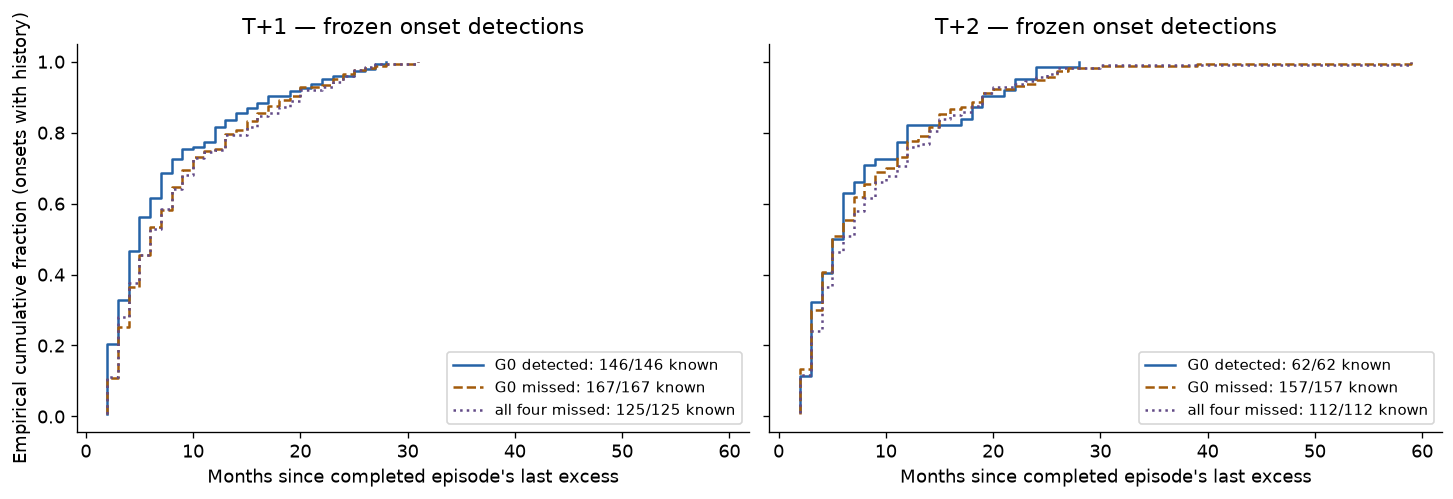

In [11]:
alerts = b.loc[b.arm.isin(MODELS)].pivot(index=PAIR, columns="arm", values="alert")
assert alerts.notna().all().all()
analysis = analysis.merge(alerts.reset_index(), on=PAIR, validate="one_to_one")
analysis["models_alerting"] = analysis[MODELS].sum(axis=1)
old_multiplicity = read(EDA + "/multiplicity.csv")
new_multiplicity = (
    analysis.loc[analysis.outcome.ne("continuation")]
    .assign(outcome=lambda f: f.outcome.replace({"no_excess": "non_excess"}))
    .groupby(["horizon", "year", "outcome", "models_alerting"])
    .size()
    .rename("rows")
    .reset_index()
)
check = old_multiplicity.merge(
    new_multiplicity,
    on=["horizon", "year", "outcome", "models_alerting"],
    suffixes=("_old", "_new"),
    how="outer",
    validate="one_to_one",
)
assert check.rows_old.fillna(0).eq(check.rows_new.fillna(0)).all()
miss_rows = []
for name, mask in [
    ("G0 detected", analysis.G0_OFF.eq(1)),
    ("G0 missed", analysis.G0_OFF.eq(0)),
    ("all four missed", analysis.models_alerting.eq(0)),
]:
    part = analysis.loc[analysis.truth.eq(1) & mask].copy()
    part["detection_group"] = name
    miss_rows.append(part)
missed = pd.concat(miss_rows, ignore_index=True)
TABLES["missed_distributions"] = distributions(missed, ["horizon", "detection_group"])
TABLES["missed_strata"] = distributions(
    missed, ["horizon", "target_year", "department", "detection_group"]
)
display(TABLES["missed_distributions"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained", sharex=True, sharey=True)
for h, ax in enumerate(axes, 1):
    for name, g in missed.loc[missed.horizon.eq(h)].groupby("detection_group"):
        v = np.sort(g.episode_end_recency.dropna())
        ax.step(
            v,
            np.arange(1, len(v) + 1) / len(v),
            where="post",
            color=COLORS[name],
            linestyle={"G0 detected": "-", "G0 missed": "--", "all four missed": ":"}[name],
            label=f"{name}: {len(v)}/{len(g)} known",
        )
    ax.set(
        title=f"T+{h} — frozen onset detections",
        xlabel="Months since completed episode's last excess",
    )
    ax.legend(loc="lower right", fontsize=9)
axes[0].set_ylabel("Empirical cumulative fraction (onsets with history)")
savefig(fig, "04_missed_onsets")

G0_OFF misses 167/313 and 157/219 onsets. Median recency among G0 misses versus
detections is 6 versus 5 months (T+1), and 5 versus 5.5 (T+2). The all-four-missed
subsets contain 125/112 onsets, median 6 months. Overlapping distributions do not
identify a selective rescue rule for shared errors.

## 3. O1 — Neighbor epidemiological activity

**NOT_EVALUABLE — historical geometry admission blocked.** Official source:
[DANE MGN integrated 2018 service](https://geoportal.dane.gov.co/mparcgis/rest/services/MGN2018/Serv_CapaMunicipiosInt_2018/MapServer).
Its [official announcement](https://www.dane.gov.co/index.php/actualidad-dane/5454-el-dane-actualizo-el-marco-geoestadistico-nacional-a-2018)
is dated 7 February 2022, after 2020/2021 benchmark origins. We retrieved official
service/layer metadata and queried all Meta/Tolima codes; the 76 match. The
service exposes polygons and a 2018 VERSION field, but no timeInfo/validity history
or historical boundary crosswalk to the canonical notification territories.
Canonical historical applicability remains UNVERIFIED. Matching codes cannot
certify boundary/adjacency equivalence for the study, including outside neighbors.

This is a bounded unsuccessful admission attempt, not proof that official
geometries do not exist. No geometry is admitted and no neighbor graph or spatial
signal is computed. No department substitute, unavailable-as-zero association,
self-neighbor claim or spatial-transmission interpretation is made. O1 comparisons,
seasonal/local redundancy, outside-neighbor coverage and self-exclusion validation
are **blocked/N/A**, not negative results. O2 proceeds independently.

The pinned admission bundle keeps access date, version, URLs, response bytes,
query and explicit stop reason. Reruns read those receipts without live downloads.

In [12]:
geo = json.loads((ROOT / GEO / "admission.json").read_text())
layer = json.loads((ROOT / GEO / "layer.json").read_text())
query = json.loads((ROOT / GEO / "query_attempt.json").read_text())
geo_codes = json.loads(query["body"])["features"]
assert query["status"] == 200 and len(geo_codes) == 76
assert {x["attributes"]["MPIO_CDPMP"] for x in geo_codes} == set(base.municipality_code)
assert {x["attributes"]["VERSION"] for x in geo_codes} == {2018}
assert layer.get("timeInfo") is None and not geo["admitted"]
assert n.historical_territory_applicability.eq("UNVERIFIED").all()
display(
    pd.DataFrame(
        [
            {
                "opportunity": "O1",
                "status": geo["status"],
                "official_regional_codes": len(geo_codes),
                "admitted_geometry": False,
                "shared_boundary_graph": "not built",
                "spatial_association": "not evaluable",
            }
        ]
    )
)

,opportunity,status,official_regional_codes,admitted_geometry,shared_boundary_graph,spatial_association
0,O1,NOT_EVALUABLE,76,False,not built,not evaluable


## 4. Compare opportunities, support and temporal behavior

O1's input admission failure cannot be interpreted as evidence of no spatial
information. O2 describes a new ordering representation of existing local states.
Both retain unresolved operational reporting availability. Repeated months and
shared annual shocks rule out independent-confirmation claims.

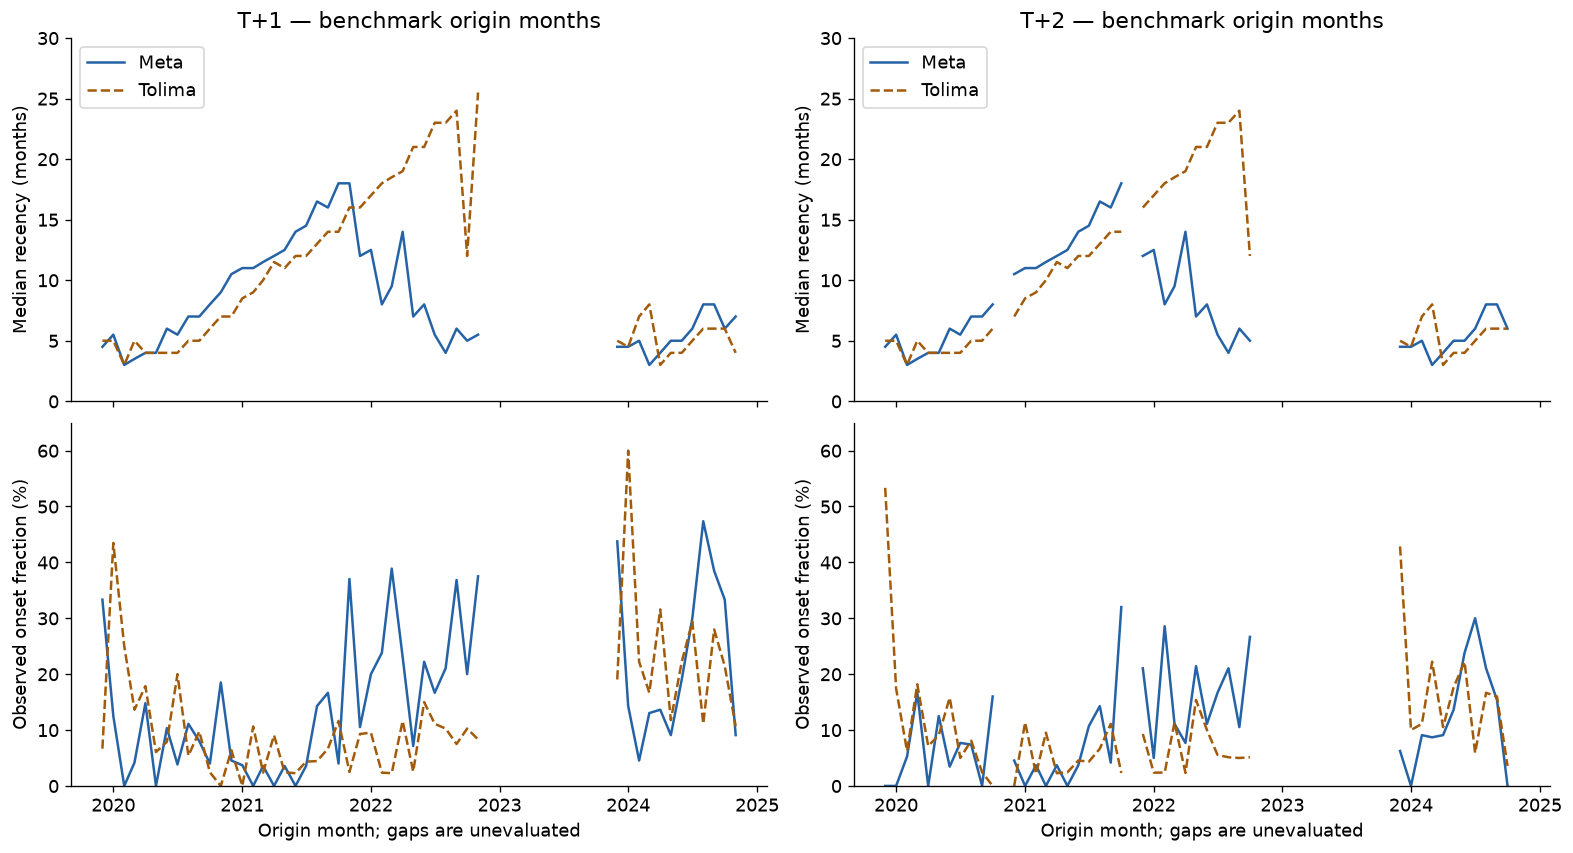

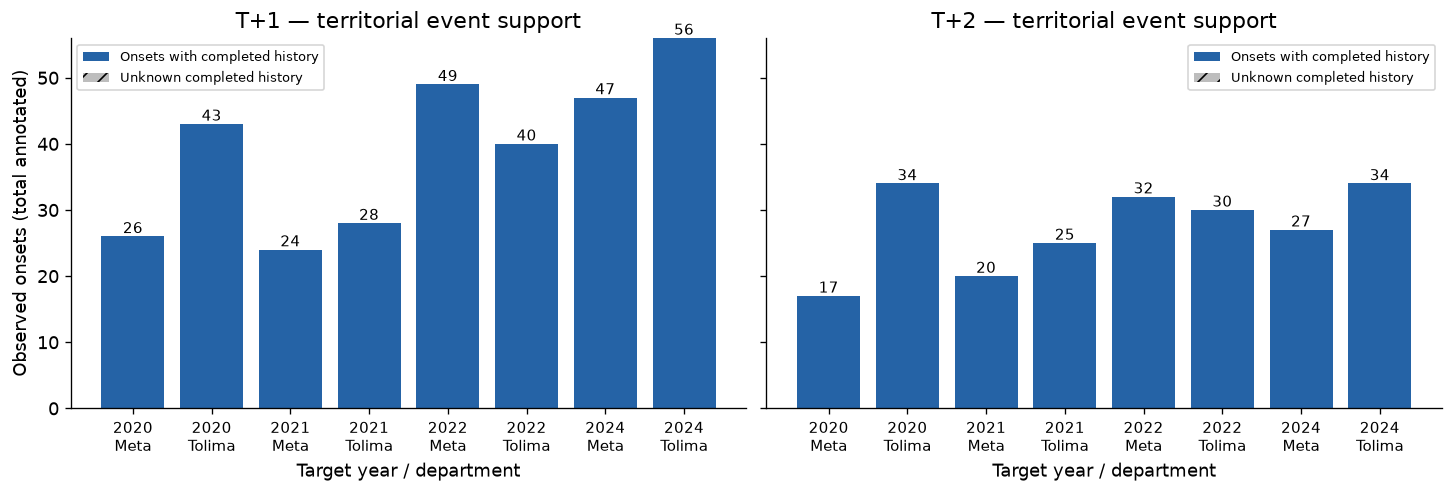

In [13]:
TABLES["temporal"] = (
    analysis.groupby(["horizon", "year_month", "department"])
    .agg(
        rows=("truth", "size"),
        onsets=("truth", "sum"),
        known_rows=("history_known", "sum"),
        median_recency=("episode_end_recency", "median"),
    )
    .reset_index()
)
TABLES["temporal"]["onset_fraction"] = TABLES["temporal"].onsets / TABLES["temporal"].rows
fig, axes = plt.subplots(2, 2, figsize=(13, 7), layout="constrained", sharex=True)
for h in [1, 2]:
    for dept, color, style in [("Meta", "#2563a6", "-"), ("Tolima", "#a25b0b", "--")]:
        g = TABLES["temporal"].loc[
            TABLES["temporal"].horizon.eq(h) & TABLES["temporal"].department.eq(dept)
        ]
        calendar = pd.period_range(g.year_month.min(), g.year_month.max(), freq="M").astype(str)
        g = g.set_index("year_month").reindex(calendar)
        x = pd.to_datetime(g.index)
        axes[0, h - 1].plot(x, g.median_recency, color=color, linestyle=style, label=dept)
        axes[1, h - 1].plot(x, 100 * g.onset_fraction, color=color, linestyle=style, label=dept)
    axes[0, h - 1].set(title=f"T+{h} — benchmark origin months", ylabel="Median recency (months)")
    axes[1, h - 1].set(
        ylabel="Observed onset fraction (%)", xlabel="Origin month; gaps are unevaluated"
    )
    axes[0, h - 1].legend(loc="upper left")
    axes[0, h - 1].set_ylim(0, 30)
    axes[1, h - 1].set_ylim(0, 65)
savefig(fig, "05_temporal_behavior")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained", sharey=True)
for h, ax in enumerate(axes, 1):
    g = (
        TABLES["history_support"]
        .loc[TABLES["history_support"].horizon.eq(h)]
        .sort_values(["target_year", "department"])
    )
    x = np.arange(len(g))
    ax.bar(x, g.known_onsets, color="#2563a6", label="Onsets with completed history")
    ax.bar(
        x,
        g.onsets - g.known_onsets,
        bottom=g.known_onsets,
        color="#bdbdbd",
        hatch="//",
        label="Unknown completed history",
    )
    for i, v in enumerate(g.onsets):
        ax.text(i, v + 0.5, str(v), ha="center", fontsize=9)
    ax.set_xticks(
        x, [f"{int(t.target_year)}\n{t.department}" for t in g.itertuples()], rotation=0, fontsize=9
    )
    ax.set(title=f"T+{h} — territorial event support", xlabel="Target year / department")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Observed onsets (total annotated)")
savefig(fig, "06_support")

Every year/department cell has at least 17 onsets and complete completed-episode
history, satisfying the aggregate support rule. Months are selected by the frozen
non-excess cohort and local events remain sparse; temporal movement and 16
repeated territorial cells are not independent replications. O1 has no admitted
signal to place on the temporal comparison.

### Validate chronology, censoring and arithmetic

Prefix invariance checks every distinct benchmark origin: truncate the source
before T, append an unknown T, and compare the signal to the full scan. A synthetic
sequence covers left censoring, active episodes, clearance at T, gaps and unknowns.
Recalculate historical episode bounds directly from original states. These checks
validate chronology and arithmetic, not operational availability or scientific gain.

In [14]:
# Meaningful boundary cases; synthetic data are validation only, never findings.
toy = pd.DataFrame(
    {
        "municipality_code": ["00000"] * 10,
        "year_month": pd.period_range("2020-01", periods=10, freq="M").astype(str),
        "zona_canal_t": [
            "EXCESO",
            "SEGURIDAD",
            "EXCESO",
            "EXCESO",
            "SEGURIDAD",
            "SEGURIDAD",
            None,
            "EXCESO",
            "SEGURIDAD",
            "SEGURIDAD",
        ],
    }
)
toy_f, toy_e = episode_history(toy)
assert toy_f.episode_end_recency.iloc[:5].isna().all()
assert toy_f.episode_end_recency.iloc[5] == 2
assert toy_f.episode_end_recency.iloc[7:].isna().all()
assert len(toy_e) == 1 and toy_e.completed_duration.iloc[0] == 2
gap_toy = toy.drop(index=5)
gap_features, _ = episode_history(gap_toy)
assert gap_features.loc[gap_features.year_month.ge("2020-07"), "episode_end_recency"].isna().all()
prefix_checks = 0
for t in sorted(analysis.year_month.unique()):
    prefix = history.loc[history.year_month.lt(t)].copy()
    tail = history.loc[history.year_month.eq(t)].copy()
    tail["zona_canal_t"] = None
    prefix_features, _ = episode_history(pd.concat([prefix, tail], ignore_index=True))
    a = features.loc[features.year_month.eq(t)].set_index(KEYS)
    z = prefix_features.loc[prefix_features.year_month.eq(t)].set_index(KEYS)
    pd.testing.assert_frame_equal(a, z)
    prefix_checks += len(a)
state_lookup = history.set_index(KEYS).zona_canal_t.to_dict()
for e in episodes.itertuples():
    s, end, c = [
        pd.Period(v, freq="M") for v in [e.episode_start, e.episode_end, e.clearance_month]
    ]
    assert state_lookup[e.municipality_code, str(s - 1)] != "EXCESO"
    assert all(
        state_lookup[e.municipality_code, str(m)] == "EXCESO"
        for m in pd.period_range(s, end, freq="M")
    )
    assert state_lookup[e.municipality_code, str(c)] != "EXCESO" and c == end + 1
# Outcomes are audited separately; no future state enters episode_history.
for row in analysis.itertuples():
    target = pd.Period(row.target_month, freq="M")
    prev = state_lookup[row.municipality_code, str(target - 1)]
    curr = state_lookup[row.municipality_code, str(target)]
    assert row.target_excess == (curr == "EXCESO")
    assert row.truth == (prev != "EXCESO" and curr == "EXCESO")
for h, g in analysis.groupby("horizon"):
    bands_h = bands.loc[bands.horizon.eq(h)]
    assert bands_h.rows.sum() == len(g) and bands_h.onsets.sum() == g.truth.sum()
# All input payloads must retain their exact pre-analysis bytes.
for rel, expected in list(SOURCES.items()):
    track(rel, expected)
print(
    f"PASS: {prefix_checks} prefix checks; {len(episodes)} completed episodes; "
    "exact pairing and source preservation"
)

PASS: 3648 prefix checks; 1326 completed episodes; exact pairing and source preservation


## 5. Scientific synthesis and immutable derived publication

The output below is the numerical receipt for the findings and conclusions.
Scientific statuses do not demonstrate predictive improvement. O1 is not evaluable;
O2's final interpretation is recorded beside the executed results and in the
linked conclusions. No automatic predictor selection, EXP-DELTA02 or model fit.
Only aggregate outputs are saved in this notebook. The private publication retains
new signal audits and necessary aggregate tables, not historical score copies.

1. Recency retains variation beyond the six state summaries (1,712/2,653 and
   1,531/2,422 rows lie in equal-summary groups with different recencies).
2. Neighbor association cannot be measured without admitted historical adjacency.
3. Start/end recency encode the same completed episode, differing by duration;
   primary recency correlates strongly with recent excess count (−0.694/−0.692).
4. Raw patterns differ by territory/year; calendar-centered directions align,
   but weak association and repeated data do not establish generality.
5. Missed onsets show broad overlap with detections, without a consistent
   horizon-specific separation or selective rescue evidence.
6. Consolidated notifications, H5 proxy, consumed years, selection, dependence,
   weak conditional support and missing as-of vintages prevent gain claims.
7. A future single-feature, paired ablation could test the O2 representation;
   its design must guard false-alert burden, temporal roles and territorial
   stability. No predictive experiment is started or authorized by this result.


In [15]:
summary = {
    "rows": {str(h): len(g) for h, g in analysis.groupby("horizon")},
    "onsets": {str(h): int(g.truth.sum()) for h, g in analysis.groupby("horizon")},
    "known_history": {str(h): int(g.history_known.sum()) for h, g in analysis.groupby("horizon")},
    "completed_episodes_through_2024": len(episodes),
    "prefix_checks": prefix_checks,
    "O1": "NOT_EVALUABLE",
    "O2": "EXPLORATORY_SIGNAL_FOUND",
    "G5": "NOT_APPROVED",
    "champion": "not_selected",
}
display(pd.DataFrame([summary]))
display(TABLES["associations"].loc[TABLES["associations"].scope.eq("horizon")])
display(TABLES["missed_distributions"])
# Bind code cells, predeclared methodology, settings, exact source bytes and versions.
notebook = nbformat.read(ROOT / "notebooks/eda_epidemiological_signals.ipynb", as_version=4)
source_cells = [
    {"cell_type": c.cell_type, "source": c.source}
    for c in notebook.cells
    if c.cell_type == "code" or "### Fixed design and assumptions" in c.source
]
settings = {
    "schema": "eda-exp02-phase-b-settings-v1",
    "history_end": "2024-12",
    "observation_cut": "strictly before T",
    "primary": "episode_end_recency",
    "bands": [1, 3, 6, 12, 24, "infinity", "unknown"],
    "support": {"rows": 30, "onsets": 5, "non_onsets": 5},
    "opportunities": {
        "O1": "NOT_EVALUABLE",
        "O2": "EXPLORATORY_SIGNAL_FOUND",
    },
    "fits": 0,
    "calibrations": 0,
    "threshold_searches": 0,
    "inference_calls": 0,
}
payloads = {name + ".csv": serialize_table(table) for name, table in TABLES.items()}
payloads["settings.json"] = json_bytes(settings)
payloads["summary.json"] = json_bytes(summary)
body = {
    "schema": "eda-exp02-phase-b-publication-v1",
    "sources": SOURCES,
    "source_cells_sha256": bytes_record(canonical_bytes(source_cells))["sha256"],
    "versions": {
        p: importlib.metadata.version(p) for p in ["numpy", "pandas", "matplotlib", "scipy"]
    },
    "G5": "NOT_APPROVED",
    "champion": "not_selected",
    "files": {name: bytes_record(v) for name, v in payloads.items()},
}
bundle_id = bytes_record(canonical_bytes(body))["sha256"]
manifest = {**body, "bundle_id": bundle_id}
payloads["manifest.json"] = json_bytes(manifest)
publication = publish_bundle(ROOT / "data/processed/eda_exp02", bundle_id, payloads)
print("Publication:", publication.relative_to(ROOT))
print("Manifest SHA-256:", bytes_record(payloads["manifest.json"])["sha256"])
print("PASS: atomic publication; exact-byte reuse only; previous publications unchanged")

,rows,onsets,known_history,completed_episodes_through_2024,prefix_checks,O1,O2,G5,champion
0,"{'1': 2653, '2': 2422}","{'1': 313, '2': 219}","{'1': 2653, '2': 2422}",1326,3648,NOT_EVALUABLE,EXPLORATORY_SIGNAL_FOUND,NOT_APPROVED,not_selected


,scope,horizon,rows,onsets,rho,calendar_centered_rho,supported,department,target_year
0,horizon,1,2653,313,-0.126086,-0.098134,True,NaN,NaN
1,horizon,2,2422,219,-0.097372,-0.092489,True,NaN,NaN


,horizon,detection_group,rows,known,unknown,onsets,q10,q25,median,q75,q90
0,1,G0 detected,146,146,0,146,2.0,3.0,5.0,9.0,17.0
1,1,G0 missed,167,167,0,167,2.0,3.5,6.0,11.5,19.0
2,1,all four missed,125,125,0,125,2.0,3.0,6.0,12.0,20.0
3,2,G0 detected,62,62,0,62,2.1,3.0,5.5,11.0,19.0
4,2,G0 missed,157,157,0,157,2.0,3.0,5.0,12.0,19.0
5,2,all four missed,112,112,0,112,2.0,4.0,6.0,12.0,19.0


Publication: data/processed/eda_exp02/de2062498abb6e309fc01ea28f10d73a283ce6f8507958f1d1c0a9b63591f605
Manifest SHA-256: bb67e6551fca23220129f763f80070a2e66c8591f2b5c3cb7d0425598dfe58b0
PASS: atomic publication; exact-byte reuse only; previous publications unchanged
